# From Raw Data to Multiple Linear Regression — One Shot Class

### EDA → Preprocessing → Outlier Handling → Encoding → Scaling → Linear Regression (from scratch + sklearn)

**Dataset:** A medical insurance charges dataset (in the style of the popular Kaggle "Medical Cost Personal Datasets"), with **missing values** and **outliers** intentionally present so we can practice fixing them.

Columns: `age`, `sex`, `bmi`, `children`, `smoker`, `region`, `charges` (target — what we want to predict).

> Run the cells top to bottom. Markdown cells before each code block explain **why** we do a step, not just **how**.


## 0. Load the Dataset

Upload `insurance_teaching.csv` (provided) using the file upload button on the left panel in Colab, or run the cell below to upload via a dialog.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
df = pd.read_csv("./insurance_teaching.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,56,male,38.6,2,no,southwest,28746.06
1,46,female,25.8,4,no,NaN,25846.73
2,32,male,29.1,2,no,northwest,21267.06
3,60,male,26.4,1,no,northeast,25905.71
4,25,female,28.2,0,no,southwest,13643.39


## 1. Exploratory Data Analysis (EDA)

**Why?** Before touching any model, we must understand:

- What kind of data do we have (numeric vs categorical)?
- Is there missing data?
- Are there outliers?
- How are features related to the target (`charges`)?

Skipping EDA is the #1 reason models fail silently — you build on assumptions that aren't true.


In [2]:
df.shape

(400, 7)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       400 non-null    int64  
 1   sex       400 non-null    str    
 2   bmi       380 non-null    float64
 3   children  400 non-null    int64  
 4   smoker    400 non-null    str    
 5   region    385 non-null    str    
 6   charges   400 non-null    float64
dtypes: float64(2), int64(2), str(3)
memory usage: 22.0 KB


In [4]:
# summary stats for numeric columns -> spot unusually high max/min (possible outliers)
df.describe()

,age,bmi,children,charges
count,400.000000,380.000000,400.000000,400.000000
mean,41.297500,30.479973,1.965000,28083.784908
std,13.421973,6.842728,1.443601,12523.219307
min,18.000000,13.300000,0.000000,8649.680000
25%,30.000000,25.975000,1.000000,20951.977500
50%,42.000000,30.300000,2.000000,25073.905000
75%,52.000000,34.900000,3.000000,30009.400000
max,64.000000,64.471284,4.000000,125837.030392


In [5]:
# summary for categorical columns
#! df.describe(include="object")  This doesn't works in VS Code
df.describe(include="str")

,sex,smoker,region
count,400,400,385
unique,2,2,4
top,male,no,northeast
freq,207,328,104


In [6]:
# how many missing values per column?
df.isnull().sum()

age          0
sex          0
bmi         20
children     0
smoker       0
region      15
charges      0
dtype: int64

<Axes: xlabel='charges', ylabel='Count'>

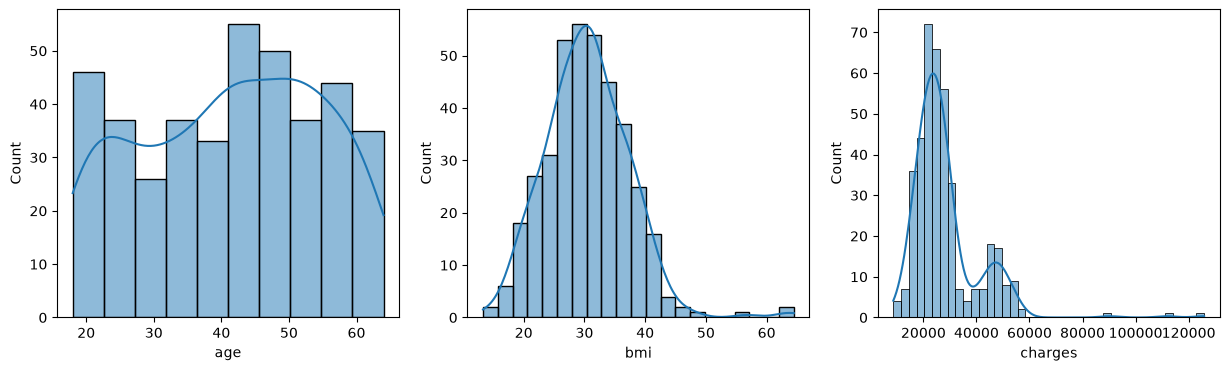

In [7]:
# Univariate: distribution of numeric columns
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df["age"], kde=True, ax=axes[0])
sns.histplot(df["bmi"], kde=True, ax=axes[1])
sns.histplot(df["charges"], kde=True, ax=axes[2])

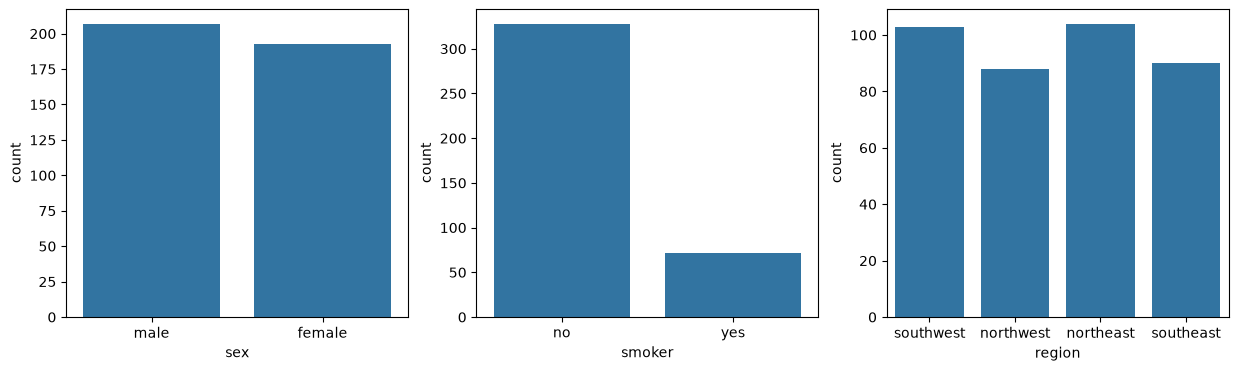

In [8]:
# Categorical counts
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(x="sex", data=df, ax=axes[0])
sns.countplot(x="smoker", data=df, ax=axes[1])
sns.countplot(x="region", data=df, ax=axes[2])

plt.show()

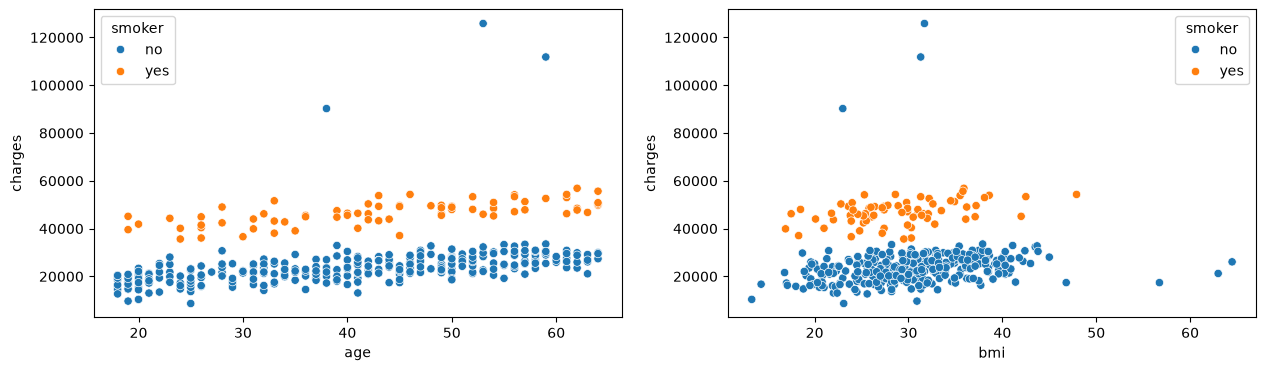

In [9]:
# Bivariate: relationship with target
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

sns.scatterplot(x="age", y="charges", hue="smoker", data=df, ax=axes[0])
sns.scatterplot(x="bmi", y="charges", hue="smoker", data=df, ax=axes[1])
plt.show()

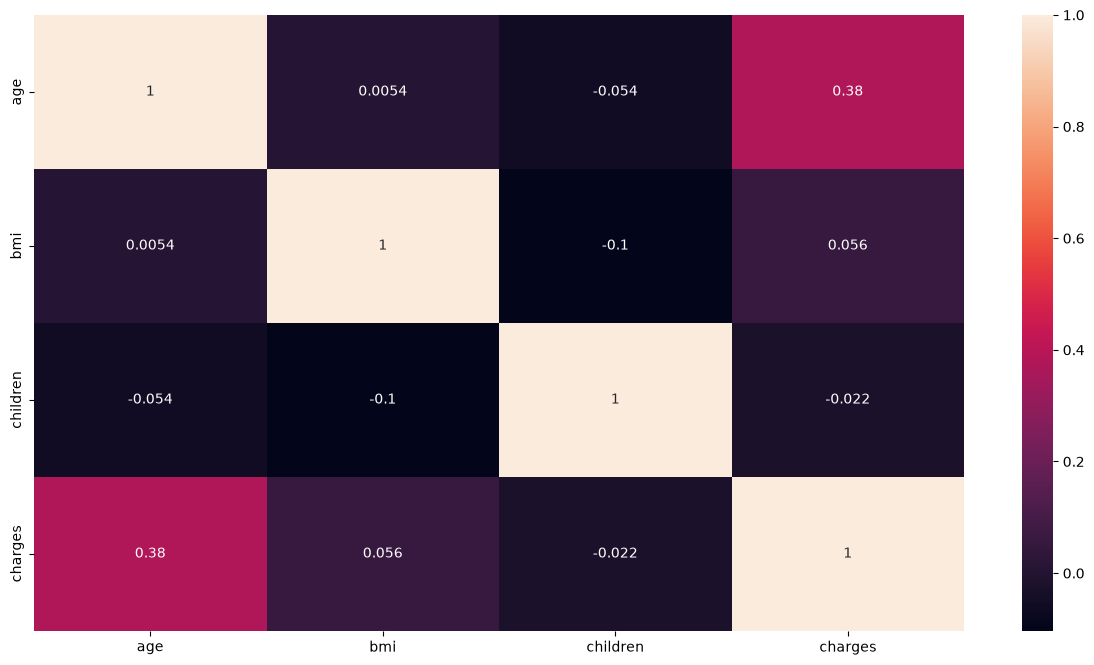

In [10]:
# Correlation heatmap for numeric features

plt.figure(figsize=(15, 8))
sns.heatmap(df[["age", "bmi", "children", "charges"]].corr(), annot=True)
plt.show()

**Takeaway from EDA:** `smoker` clearly separates charges into two groups, `age` and `bmi` show a positive trend with `charges`, and we can already see a few extreme points in `charges` and `bmi` — this is a clue we'll deal with in the outlier section.


## 2. Train-Test Split & Missing Value Handling

**Why split _before_ handling missing values / outliers / scaling?**
If we compute things like the mean (to fill missing values) or min/max (to scale) using the _entire_ dataset including test data, information from the test set "leaks" into training. The model would look better than it really is. This is called **data leakage**. Rule: **fit on train, apply (transform) on both train and test.**


In [11]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["charges"])
y = df["charges"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
X_train.shape, X_test.shape

((320, 6), (80, 6))

### Handling missing values

Options:

- **Drop rows/columns** — simplest, but wastes data.
- **Impute** — fill with mean/median (numeric) or mode (categorical). Median is preferred over mean when outliers are present (mean gets pulled by extreme values).

We'll impute `bmi` with the **median** of the training set, and `region` with the **mode** of the training set.


In [12]:
X_train.isnull().sum()

age          0
sex          0
bmi         17
children     0
smoker       0
region      13
dtype: int64

In [13]:
bmi_median = X_train["bmi"].median()
region_mode = X_train["region"].mode()[0]

In [14]:
for data in [X_train, X_test]:
    data["bmi"].fillna(bmi_median, inplace=True)
    data["region"].fillna(region_mode, inplace=True)


X_train.isnull().sum()

/tmp/ipykernel_6854/1619529766.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  data["bmi"].fillna(bmi_median, inplace=True)
/tmp/ipykernel_6854/1619529766.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to

age          0
sex          0
bmi         17
children     0
smoker       0
region      13
dtype: int64

In [15]:
X_test.isnull().sum()

age         0
sex         0
bmi         3
children    0
smoker      0
region      2
dtype: int64

## 3. Prerequisites of Outlier Handling

Before removing/capping anything, ask:

1. **Is it a genuine data-entry error, or a real (rare) observation?** (e.g., BMI of 70 could be a typo — or a real extreme case.)
2. **Does the feature's distribution matter for the method?** IQR/Z-score assume unimodal, roughly symmetric/normal-ish distributions. Check with a histogram/boxplot first (we already did this in EDA).
3. **Will removing it hurt the model?** If outliers are rare-but-real and business-relevant, capping (winsorizing) is safer than deleting.
4. **Only treat outliers on the training set stats**, then apply the same bounds to the test set (same leakage rule as before).

So the correct order is always: **Visualize → Decide method → Compute bounds on train → Apply to train & test.**


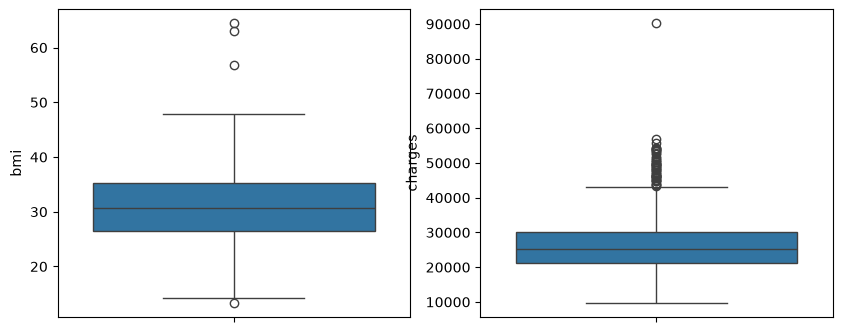

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.boxplot(y=X_train["bmi"], ax=axes[0])
sns.boxplot(y=y_train, ax=axes[1])

plt.show()

## 4. Outlier Detection & Handling

**IQR (Interquartile Range) method:**

- Q1 = 25th percentile, Q3 = 75th percentile, IQR = Q3 − Q1
- Lower bound = Q1 − 1.5×IQR, Upper bound = Q3 + 1.5×IQR
- Anything outside these bounds is flagged as an outlier.

We'll **cap (winsorize)** rather than delete, so we don't lose rows.


In [17]:
def get_iqr_bounds(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return lower, upper

In [18]:
bmi_lower, bmi_upper = get_iqr_bounds(X_train["bmi"])

charges_lower, charges_upper = get_iqr_bounds(y_train)

In [19]:
bmi_lower

np.float64(13.574999999999998)

In [20]:
bmi_upper

np.float64(48.175000000000004)

In [21]:
charges_lower

np.float64(7971.462499999994)

In [22]:
charges_upper

np.float64(43232.162500000006)

In [23]:
X_train["bmi"] = X_train["bmi"].clip(lower=bmi_lower, upper=bmi_upper)
X_test["bmi"] = X_test["bmi"].clip(lower=bmi_lower, upper=bmi_upper)

In [24]:
y_train = y_train.clip(lower=charges_lower, upper=charges_upper)
y_test = y_test.clip(lower=charges_lower, upper=charges_upper)

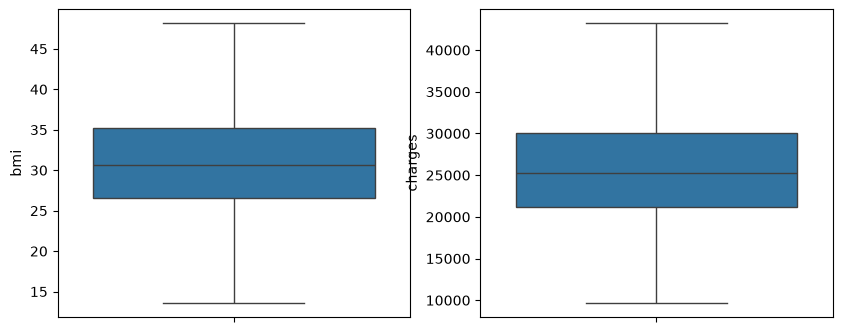

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.boxplot(y=X_train["bmi"], ax=axes[0])
sns.boxplot(y=y_train, ax=axes[1])

plt.show()

## 5. Encoding Categorical Variables

**Why?** ML models (especially linear regression) only understand numbers. `sex`, `smoker`, `region` are text — we must convert them.

- **Label Encoding**: assigns 0,1,2... — good for **binary** or **ordinal** categories (e.g., `sex`, `smoker` — only 2 categories, no ordering problem).
- **One-Hot Encoding**: creates a separate 0/1 column per category — used for **nominal** categories with no natural order (e.g., `region`), so the model doesn't wrongly assume `northeast > southwest` etc.


In [26]:
X_train_enc = X_train.copy()
X_test_enc = X_test.copy()


X_train_enc["sex"] = X_train_enc["sex"].map({"male": 1, "female": 0})
X_test_enc["sex"] = X_test_enc["sex"].map({"male": 1, "female": 0})

X_train_enc["smoker"] = X_train_enc["smoker"].map({"yes": 1, "no": 0})
X_test_enc["smoker"] = X_test_enc["smoker"].map({"yes": 1, "no": 0})

# one hot encoding

X_train_enc = pd.get_dummies(X_train_enc, columns=["region"], drop_first=True)
X_test_enc = pd.get_dummies(X_test_enc, columns=["region"], drop_first=True)

In [27]:
X_test_enc = X_test_enc.reindex(columns=X_train_enc.columns, fill_value=0)

In [28]:
X_train_enc

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest
3,60,1,26.4,1,0,False,False,False
18,41,1,40.1,2,0,False,True,False
202,20,1,33.3,1,0,False,False,False
250,35,1,28.4,4,0,False,True,False
274,33,1,20.7,3,0,False,True,False
...,...,...,...,...,...,...,...,...
71,27,0,33.9,3,0,False,False,True
106,52,1,27.7,3,0,False,False,False
270,26,1,32.9,3,0,False,False,False
348,38,0,35.7,1,0,False,False,True


## 6. Feature Scaling

**Why?** `age` ranges ~18-64, `bmi` ~15-55, but `children` ~0-4. Linear regression solved via **gradient descent** is sensitive to scale — features with larger ranges dominate the gradient and slow/mess up convergence. Scaling puts all numeric features on comparable footing.

- **StandardScaler**: (x − mean) / std → mean 0, std 1. Good default, especially for linear models.
- **MinMaxScaler**: squashes values into [0,1]. Useful when you need a bounded range.

Again: **fit the scaler on train only**, then transform both.


In [29]:
from sklearn.preprocessing import StandardScaler

num_cols = ["age", "bmi", "children"]

scaler = StandardScaler()

X_train_scaled = X_train_enc.copy()
X_test_scaled = X_test_enc.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train_enc[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test_enc[num_cols])

X_train_scaled.head()

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest
3,1.343596,1,-0.689530,-0.692739,0,False,False,False
18,-0.059782,1,1.429285,-0.002158,0,False,True,False
202,-1.610884,1,0.377611,-0.692739,0,False,False,False
250,-0.502954,1,-0.380214,1.379004,0,False,True,False
274,-0.650678,1,-1.571081,0.688423,0,False,True,False


## 7. AI / ML Overview & Simple Linear Regression

**Quick mental model:**

- **AI** = machines mimicking intelligent behavior (broad umbrella).
- **ML** = a _subset_ of AI: instead of hand-coding rules, the machine **learns patterns from data**.
- **Supervised Learning**: we have inputs (X) _and_ correct outputs (y) — the model learns the mapping. Regression (predicting a number) and Classification (predicting a category) are the two main types.

**Linear Regression** is the simplest supervised algorithm: it assumes the target is a **weighted sum of the inputs**:

`y = m*x + c` (simple LR, one feature) → we're finding the best-fit line.

**How do we find the best `m` and `c`?** We define a **Cost Function** — Mean Squared Error (MSE) — that measures how wrong our line is, and we minimize it using **Gradient Descent**: repeatedly nudge `m` and `c` in the direction that reduces the error, using derivatives (slopes) of the cost function.

Let's implement this **from scratch** using just `bmi` to predict `charges`, so you see exactly what's happening under the hood before we use a library.


In [30]:
x = X_train_scaled["bmi"].values
y_vals = y_train.values

m, c = 0.0, 0.0

In [31]:
learning_rate = 0.01

epochs = 1000

n = len(x)

loss_history = []


for i in range(epochs):
    y_pred = m * x + c

    error = y_vals - y_pred

    mse = np.mean(error**2)

    loss_history.append(mse)

    dm = (-2 / n) * np.sum(x * error)

    dc = (-2 / n) * np.sum(error)

    m = m - learning_rate * dm
    c = c - learning_rate * dc

print(m, c)
print(loss_history[-1])

nan nan
nan


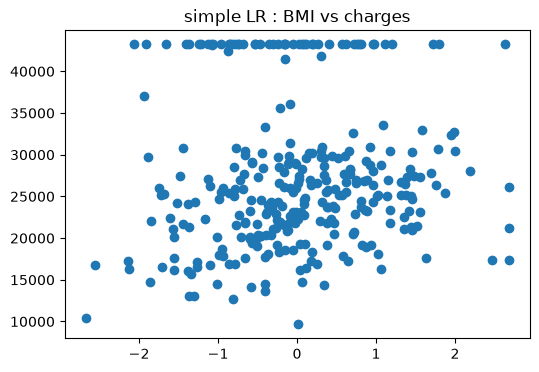

In [32]:
plt.figure(figsize=(6, 4))

plt.scatter(x, y_vals, label="actual data")

plt.plot(np.sort(x), m * np.sort(x) + c, color="red")

plt.title("simple LR : BMI vs charges")
plt.show()

**What just happened, in plain words:** we started with a random line, measured how bad it was (MSE), computed which direction to move `m` and `c` to reduce that error, took a small step, and repeated. That loop _is_ "training" a model.


## 8. Multiple Linear Regression with scikit-learn

Now that you've seen the mechanics, let's do the same thing the **practical, production way** — using `sklearn`, which handles the optimization internally (via the Normal Equation / least squares, not manual gradient descent) and gives us ready-made evaluation metrics.


In [33]:
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

model = LinearRegression()

model.fit(X_train_scaled, y_train)

ValueError: Input X contains NaN.
LinearRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [ ]:
y_pred = model.predict(X_test_scaled)

In [ ]:
for col, coef in zip(X_train_scaled.columns, model.coef_):
    print(f"{col}: {coef}")

print(model.intercept_)

In [ ]:
mse = mean_squared_error(y_test, y_pred)
mse

In [ ]:
mae = mean_absolute_error(y_test, y_pred)

mae

In [ ]:
r2 = r2_score(y_test, y_pred)
r2

In [ ]:
plt.figure(figsize=(6, 5))

plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()], [y_train.min(), y_train.max()])
plt.show()

### Wrap-up

| Step           | What we did                                         | Why                                                        |
| -------------- | --------------------------------------------------- | ---------------------------------------------------------- |
| EDA            | Explored shape, types, distributions, relationships | Understand the data before modeling                        |
| Split          | 80/20 train-test split                              | Evaluate on unseen data, avoid leakage                     |
| Missing values | Median/mode imputation (fit on train)               | Models can't handle NaNs                                   |
| Outliers       | IQR method, capped using train bounds               | Extreme values distort mean/variance & model fit           |
| Encoding       | Label + One-Hot                                     | Convert text categories to numbers                         |
| Scaling        | StandardScaler                                      | Put features on comparable scale for gradient-based models |
| Simple LR      | From scratch with gradient descent                  | See exactly how a line is "learned"                        |
| Multiple LR    | From scratch (vectorized)                           | Extend to many features                                    |
| sklearn LR     | `LinearRegression()`                                | Production-ready, fast, well-tested                        |

**Next steps for students:** try Ridge/Lasso regression, polynomial features, or apply this same pipeline to a Kaggle dataset of their choice.
